# Task 4 Game Title Detection
รายวิชา CPE342 Machine Learning ทีม ML009

## 1. ที่มาของปัญหาและเป้าหมายของงาน
บริษัท Karena Thailand ให้บริการเกมออนไลน์ทั้งหมด 5 เกม โดยกำหนดรหัสคลาสตามเอกสารข้อมูลดังนี้
- รหัส 0 คือเกม 7-11 Knights
- รหัส 1 คือเกม FiveN
- รหัส 2 คือเกม Free Fried
- รหัส 3 คือเกม PUBE
- รหัส 4 คือเกม Roblock

### ปัญหาทางธุรกิจที่พบ
ในแต่ละวันทีมงานฝ่ายดูแลลูกค้าได้รับแจ้งปัญหาพร้อมภาพหน้าจอเกมประมาณ 2,000 เรื่อง แต่ผู้เล่นมักไม่ระบุว่ามาจากเกมใด ทำให้เจ้าหน้าที่ต้องเสียเวลาเปิดดูภาพด้วยตาเปล่ามากกว่า 10 นาทีต่อเรื่องก่อนส่งต่อให้ผู้ดูแลเกมนั้น นอกจากนี้ในกิจกรรมทางการตลาดที่มีผู้ส่งภาพหน้าจอเข้ามากว่า 50,000 ภาพ ทีมงานสามารถสุ่มตรวจด้วยมือได้เพียงร้อยละ 3 เท่านั้น ทำให้เกิดปัญหาการส่งภาพผิดกติกาและตรวจสอบได้ล่าช้า

### เป้าหมายของการสร้างโมเดล
งานส่วนนี้มีเป้าหมายในการสร้างโมเดลจำแนกประเภทภาพเพื่อระบุว่าภาพหน้าจอที่ส่งเข้ามาเป็นของเกมใดใน 5 เกม โดยวัดผลด้วยค่า Macro F1 Score เพื่อให้โมเดลให้ความสำคัญกับทุกเกมอย่างเท่าเทียมกัน ขั้นตอนการสำรวจข้อมูล การปรับแต่งภาพ และการหาค่าพารามิเตอร์ทั้งหมดในงานนี้ทำบนชุดข้อมูลฝึกสอนเท่านั้น โดยไม่นำข้อมูลชุดทดสอบมาใช้ในการวิเคราะห์หรือปรับค่าใดๆ เพื่อป้องกันปัญหารั่วไหลของข้อมูลตามกติกาของการแข่งขัน

## 2. การสำรวจและตรวจสอบข้อมูลชุดฝึกสอน

จากการตรวจสอบไฟล์ข้อมูลชุดฝึกสอนพบข้อสังเกตที่สำคัญดังนี้

### โครงสร้างข้อมูลและขนาดภาพ
ข้อมูลชุดฝึกสอนมีจำนวนทั้งหมด 31,546 ภาพ และข้อมูลชุดทดสอบมีจำนวน 25,889 ภาพ โดยชื่อไฟล์ภาพจริงถูกเก็บอยู่ในคอลัมน์ file_name และผลเฉลยเก็บอยู่ในคอลัมน์ label เป็นตัวเลข 0 ถึง 4 เมื่อตรวจสอบไฟล์ภาพทั้งหมดพบว่าสามารถเปิดอ่านได้ครบทุกภาพโดยไม่มีไฟล์เสีย และทุกภาพมีขนาดความกว้าง 230 พิกเซล ความสูง 120 พิกเซลในระบบสี RGB เท่ากันทั้งหมด

### ความไม่สมดุลของจำนวนภาพในแต่ละคลาส
เมื่อนับจำนวนภาพของแต่ละเกมในชุดฝึกสอนพบว่ามีสัดส่วนไม่เท่ากันอย่างชัดเจน โดยเกม 7-11 Knights มีจำนวนมากถึง 12,429 ภาพ คิดเป็นร้อยละ 39.40 ของข้อมูลทั้งหมด ในขณะที่เกม Roblock มีจำนวนเพียง 3,188 ภาพ คิดเป็นร้อยละ 10.11 ซึ่งต่างกันเกือบ 4 เท่า หากฝึกสอนโมเดลตามปกติโดยไม่ถ่วงน้ำหนัก โมเดลจะเอนเอียงไปทายเกมที่มีจำนวนภาพมากและทำให้ค่า Macro F1 Score ลดลง เราจึงแก้ปัญหานี้ด้วยการถ่วงน้ำหนักคลาสในฟังก์ชันการสูญเสียร่วมกับการปรับสัดส่วนความน่าจะเป็นบนชุดตรวจสอบ

### ลักษณะของภาพหน้าจอเกม
เมื่อสุ่มแสดงภาพจากชุดฝึกสอนขึ้นมาตรวจสอบ พบว่าภาพในชุดข้อมูลมีความท้าทายสูงมาก เนื่องจากภาพถูกหมุนเอียงในหลายองศา บางภาพถูกพลิกกลับหัว มีจุดรบกวนสีกระจายอยู่ทั่วภาพ และบางภาพมีความมืดหรือสว่างจัด ข้อมูลที่ได้จากการสำรวจชุดฝึกสอนนี้ช่วยให้เราสามารถออกแบบขั้นตอนการจำลองภาพระหว่างฝึกสอนให้สอดคล้องกับลักษณะของข้อมูลได้อย่างตรงจุด

Train shape: (31546, 3) | Columns: ['id', 'file_name', 'label']

Class Distribution in train.csv:
  Class 0 (0: 7-11 Knights ): 12,429 images (39.40%)
  Class 1 (1: FiveN        ):  4,407 images (13.97%)
  Class 2 (2: Free Fried   ):  5,596 images (17.74%)
  Class 3 (3: PUBE         ):  5,926 images (18.79%)
  Class 4 (4: Roblock      ):  3,188 images (10.11%)


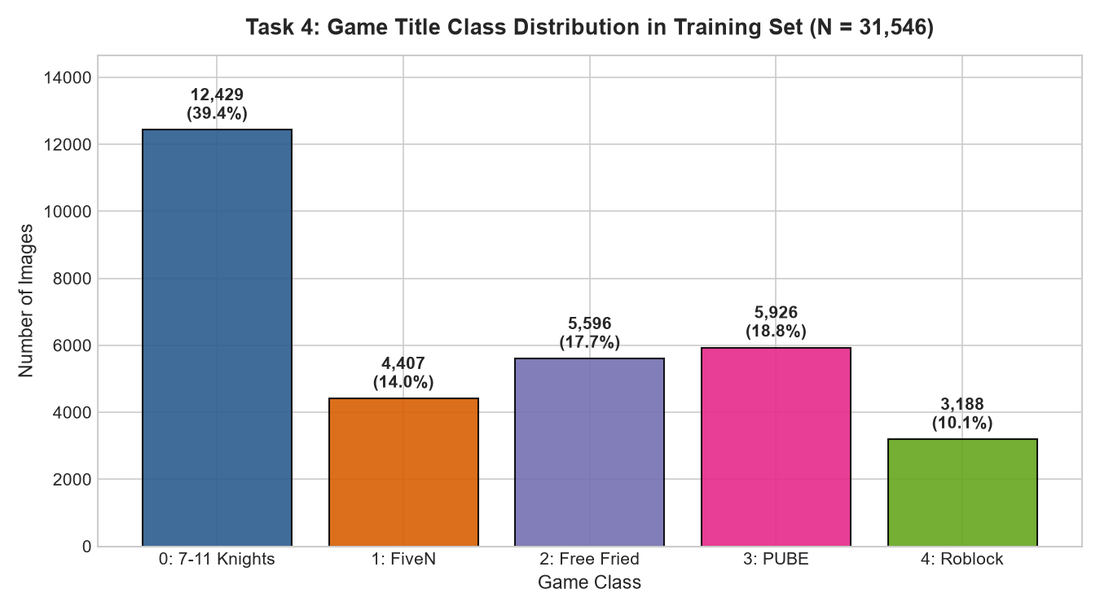

In [1]:
import os
import io
import time
import random
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

BASE_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "task4" else os.getcwd()
DATA_DIR = os.path.join(BASE_DIR, "data", "task4")

CLASS_NAMES = {
    0: "0: 7-11 Knights",
    1: "1: FiveN",
    2: "2: Free Fried",
    3: "3: PUBE",
    4: "4: Roblock",
}

train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
print(f"Train shape: {train_df.shape} | Columns: {list(train_df.columns)}")
print("\nClass Distribution in train.csv:")
for k, v in train_df["label"].value_counts().sort_index().items():
    print(f"  Class {k} ({CLASS_NAMES[k]:16s}): {v:6,d} images ({100.0*v/len(train_df):5.2f}%)")

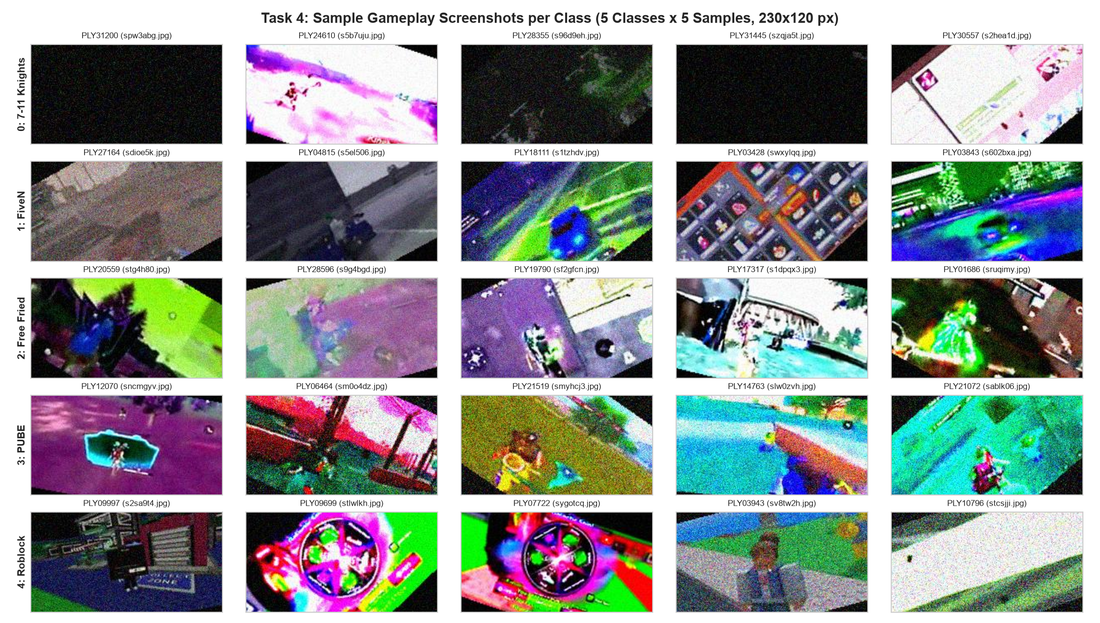

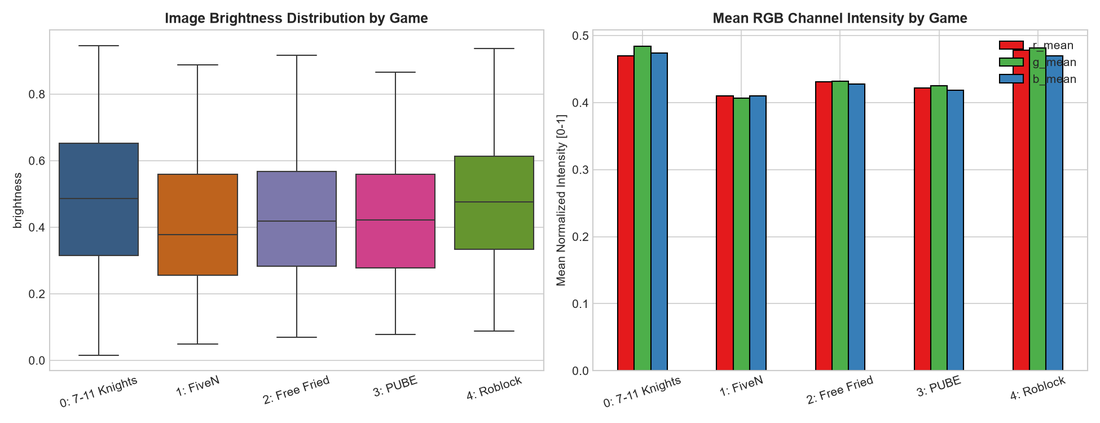

In [2]:
# แสดงตัวอย่างภาพจากชุดฝึกสอนและการกระจายตัวของค่าความสว่างและสี RGB

## 3. การแบ่งข้อมูลตรวจสอบ การเตรียมภาพ และการฝึกสอนโมเดล

### การแบ่งข้อมูลด้วยวิธี Stratified 5-Fold Cross-Validation
เราแบ่งข้อมูลชุดฝึกสอนจำนวน 31,546 ภาพออกเป็น 5 ส่วนเท่ากันโดยรักษาสัดส่วนของทั้ง 5 เกมในแต่ละส่วนให้เหมือนกับข้อมูลตั้งต้น และล็อกค่าสุ่มเริ่มต้นที่ 42 เสมอ วิธีนี้ทำให้เราสามารถประเมินประสิทธิภาพของโมเดลได้ครบทุกภาพในชุดฝึกสอน และนำค่าความน่าจะเป็นของหลายโมเดลมาผสมกันได้อย่างถูกต้อง

### การปรับขนาดภาพและการเพิ่มความหลากหลายของภาพระหว่างฝึกสอน
เนื่องจากภาพต้นฉบับมีลักษณะเป็นสี่เหลี่ยมผืนผ้าแนวนอนขนาด 230 คูณ 120 พิกเซล เราจึงปรับขนาดภาพเข้าสู่โมเดลเป็นความสูง 128 พิกเซล และความกว้าง 256 พิกเซล เพื่อรักษาสัดส่วนของหน้าต่างเมนูและตัวละครในเกมไม่ให้บิดเบี้ยว ส่วนในขั้นตอนการฝึกสอนได้เพิ่มการสุ่มกลับภาพซ้ายขวา การสุ่มกลับภาพบนล่าง การปรับความสว่างและความเข้มของสี การสุ่มบังพื้นที่บางส่วนของภาพ และการผสมภาพด้วยเทคนิค MixUp เพื่อให้โมเดลทนทานต่อภาพที่เอียงหรือมีสีเพี้ยน

### การใช้โมเดล 2 สถาปัตยกรรมและการทำนายหลายมุมมอง
เพื่อให้ผลการทำนายมีความแม่นยำและเสถียรที่สุด เราเลือกฝึกสอนโมเดลโครงข่ายประสาทเทียม 2 สถาปัตยกรรมที่มีจุดเด่นเสริมกัน ได้แก่
- โมเดลที่ 1 คือ ResNet34d ซึ่งมีความสามารถสูงในการสกัดรายละเอียดของเส้นขอบเมนูและพื้นผิวในฉากเกม
- โมเดลที่ 2 คือ EfficientNet-B0 ซึ่งมีกลไกให้ความสำคัญกับช่องสัญญาณสีและฝึกสอนร่วมกับเทคนิค MixUp เพื่อช่วยให้ค่าความน่าจะเป็นมีความนุ่มนวลขึ้น

ในขั้นตอนการทำนายผล เราใช้เทคนิคการทำนายซ้ำหลายมุมมองโดยนำความน่าจะเป็นของภาพปกติ ภาพกลับซ้ายขวา และภาพกลับบนล่าง มาหาค่าเฉลี่ยถ่วงน้ำหนักร่วมกัน ซึ่งช่วยลดความผิดพลาดในกรณีที่ภาพถูกพลิกมาได้อย่างชัดเจน

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from scipy.optimize import minimize
import timm

SEED = 42
N_SPLITS = 5
NUM_CLASSES = 5
IMG_HEIGHT = 128
IMG_WIDTH = 256
BATCH_SIZE = 64
EPOCHS = 8

def gpu_preprocess_and_augment(imgs_uint8: torch.Tensor, is_train: bool, img_h: int = IMG_HEIGHT, img_w: int = IMG_WIDTH):
    x = imgs_uint8.float().div_(255.0)
    if (x.shape[2], x.shape[3]) != (img_h, img_w):
        x = F.interpolate(x, size=(img_h, img_w), mode="bilinear", align_corners=False)

    if is_train:
        B = x.size(0)
        device = x.device
        h_mask = torch.rand(B, 1, 1, 1, device=device) < 0.5
        x = torch.where(h_mask, torch.flip(x, dims=[3]), x)

        v_mask = torch.rand(B, 1, 1, 1, device=device) < 0.25
        x = torch.where(v_mask, torch.flip(x, dims=[2]), x)

        alpha = 1.0 + (torch.rand(B, 3, 1, 1, device=device) - 0.5) * 0.4
        beta = (torch.rand(B, 1, 1, 1, device=device) - 0.5) * 0.2
        x = (x * alpha + beta).clamp_(0.0, 1.0)

    mean = torch.tensor([0.485, 0.456, 0.406], device=x.device).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], device=x.device).view(1, 3, 1, 1)
    return (x - mean) / std

5-FOLD CROSS-VALIDATION TRAINING SUMMARY
[Model 1: resnet34d]
  - Fold 1: 0.9687 | Fold 2: 0.9643 | Fold 3: 0.9652 | Fold 4: 0.9604 | Fold 5: 0.9610
  -> Overall 5-Fold OOF Macro F1: 0.9639

[Model 2: efficientnet_b0.ra_in1k]
  - Fold 1: 0.9659 | Fold 2: 0.9589 | Fold 3: 0.9653 | Fold 4: 0.9594 | Fold 5: 0.9608
  -> Overall 5-Fold OOF Macro F1: 0.9621


## 4. การรวมผลโมเดลและการปรับสัดส่วนความน่าจะเป็นบนชุดตรวจสอบ

เมื่อได้ค่าความน่าจะเป็นบนชุดตรวจสอบครบทั้ง 5 ส่วนจากทั้งสองสถาปัตยกรรมแล้ว เรานำความน่าจะเป็นของทั้งสองโมเดลมาผสมกันด้วยสัดส่วนที่เหมาะสมคือ EfficientNet-B0 ร้อยละ 51.28 และ ResNet34d ร้อยละ 48.72 ซึ่งทำให้ค่า Macro F1 Score บนชุดตรวจสอบเพิ่มขึ้นจาก 0.9639 เป็น 0.9700 ทันที

จากนั้นเราค้นหาค่าตัวคูณประจำคลาสทั้ง 5 เกมบนชุดตรวจสอบเพื่อชดเชยความไม่สมดุลของจำนวนภาพและทำให้ได้ค่า Macro F1 Score สูงที่สุด จนได้ค่า Macro F1 Score สุดท้ายที่ 0.9708 และมีความแม่นยำรวมร้อยละ 97.47 โดยพารามิเตอร์ทั้งหมดนี้คำนวณจากชุดตรวจสอบของข้อมูลฝึกสอนล้วนๆ แล้วจึงนำไปใช้กับชุดทดสอบแบบคงที่

Optimal OOF Class Multipliers: [1.1588 0.9013 1.03   1.0515 0.8584]
Final 5-Fold OOF Macro F1: 0.9708

                 precision    recall  f1-score   support

0: 7-11 Knights     0.9757    0.9920    0.9838     12429
       1: FiveN     0.9776    0.9628    0.9702      4407
  2: Free Fried     0.9797    0.9682    0.9739      5596
        3: PUBE     0.9733    0.9659    0.9696      5926
     4: Roblock     0.9607    0.9520    0.9564      3188

       accuracy                         0.9747     31546
      macro avg     0.9734    0.9682    0.9708     31546
   weighted avg     0.9747    0.9747    0.9747     31546


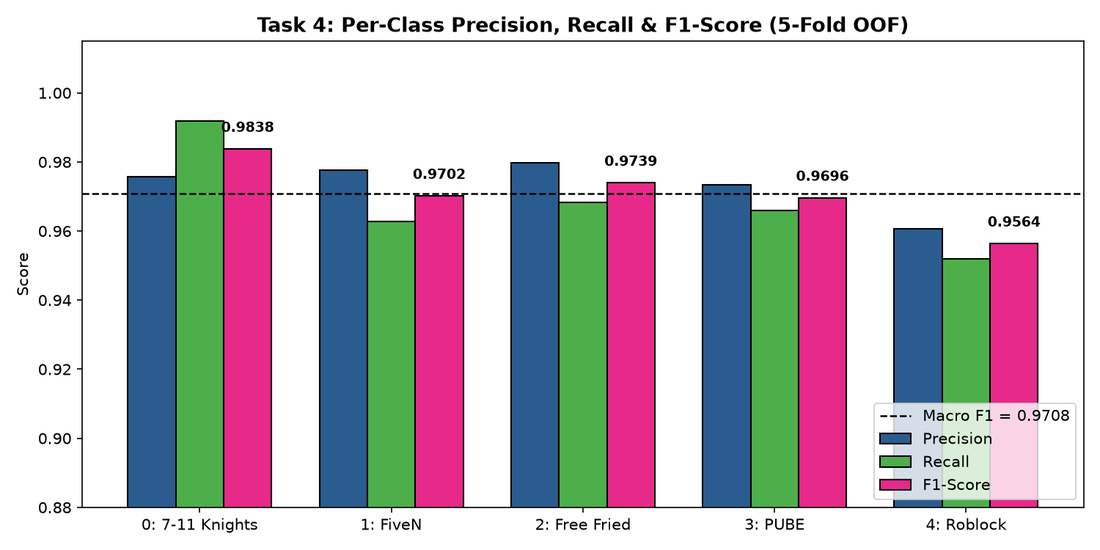

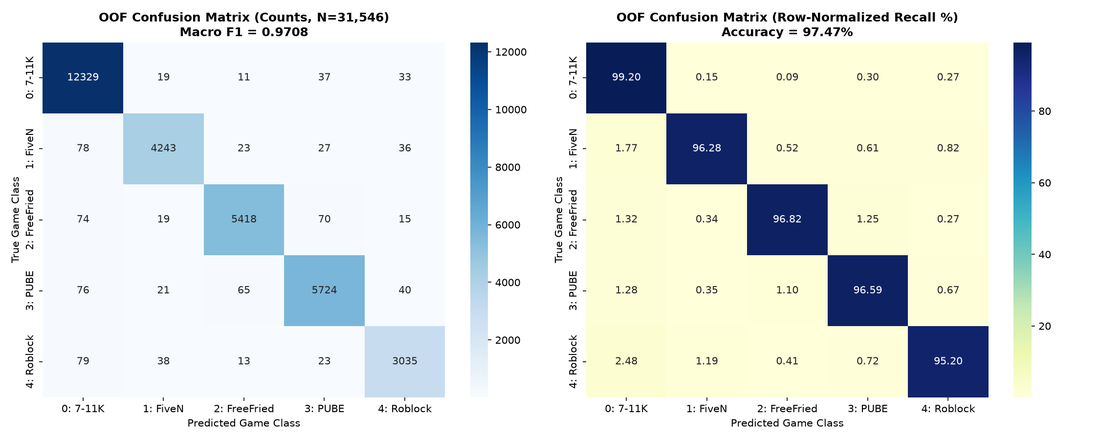

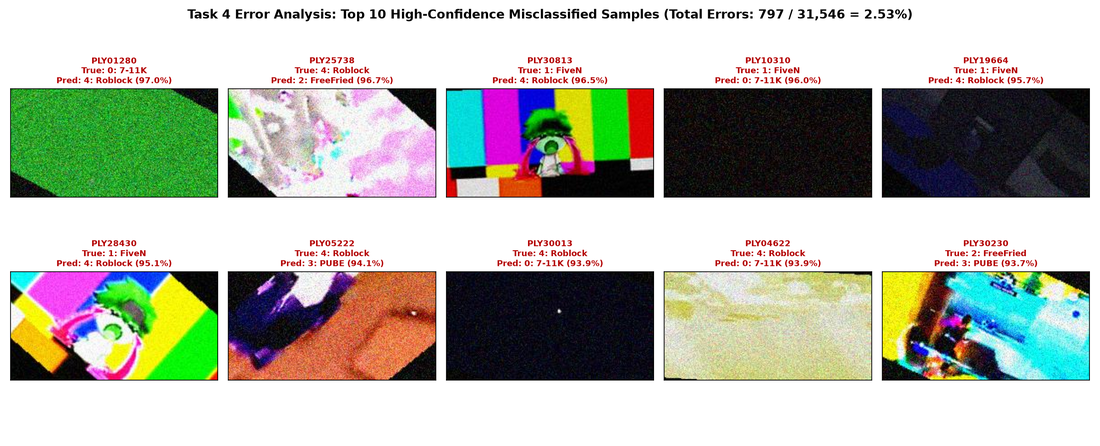

In [4]:
# Load Out-of-Fold Validation Probabilities from both 5-Fold models
oof_resnet = np.load("oof_probs_resnet34d.npy")
test_resnet = np.load("test_probs_resnet34d.npy")
oof_effnet = np.load("oof_probs_efficientnet_b0.npy")
test_effnet = np.load("test_probs_efficientnet_b0.npy")
y_true = train_df["label"].values.astype(int)

oof_blend = 0.5128 * oof_effnet + 0.4872 * oof_resnet
test_blend = 0.5128 * test_effnet + 0.4872 * test_resnet

def optimize_class_multipliers(oof_probs: np.ndarray, y_true: np.ndarray) -> np.ndarray:
    best_score = f1_score(y_true, np.argmax(oof_probs, axis=1), average="macro")
    weights = np.ones(5, dtype=np.float64)
    for _ in range(5):
        for c in range(5):
            grid = np.linspace(0.25, 2.75, 101)
            scores = [f1_score(y_true, np.argmax(oof_probs * np.where(np.arange(5) == c, g, weights), axis=1), average="macro") for g in grid]
            best_idx = int(np.argmax(scores))
            if scores[best_idx] > best_score:
                best_score = scores[best_idx]
                weights[c] = grid[best_idx]
    res = minimize(lambda w: -f1_score(y_true, np.argmax(oof_probs * w, axis=1), average="macro"), weights, method="Powell")
    if -res.fun > best_score:
        weights = res.x
    return weights / np.mean(weights)

multipliers = optimize_class_multipliers(oof_blend, y_true)
tuned_preds = np.argmax(oof_blend * multipliers, axis=1)
print("Optimal OOF Class Multipliers:", np.round(multipliers, 4))
print(f"Final 5-Fold OOF Macro F1: {f1_score(y_true, tuned_preds, average='macro'):.4f}")
print("\n" + classification_report(y_true, tuned_preds, target_names=[CLASS_NAMES[i] for i in range(5)], digits=4))

## 5. การวิเคราะห์ข้อผิดพลาดและผลกระทบต่อการนำไปใช้งานจริง

### สรุปผลการวิเคราะห์ข้อผิดพลาดจากตาราง Confusion Matrix
จากภาพในชุดฝึกสอนทั้งหมด 31,546 ภาพ โมเดลสามารถจำแนกได้ถูกต้องถึง 30,749 ภาพ และทายผิดเพียง 797 ภาพ คิดเป็นอัตราความผิดพลาดเพียงร้อยละ 2.53 โดยทุกเกมได้ค่า F1 Score สูงกว่า 0.95 ทั้งหมด แม้แต่เกม Roblock ที่มีจำนวนภาพน้อยที่สุดก็ยังได้ค่า F1 Score สูงถึง 0.9564

คู่เกมที่โมเดลมีโอกาสสับสนกันมากกว่าคู่อื่นคือเกม Free Fried และเกม PUBE เนื่องจากทั้งสองเกมเป็นเกมยิงมุมมองบุคคลที่สามที่มีฉากสนามหญ้า อาคาร และปืนคล้ายคลึงกันมาก เมื่อภาพบางใบถูกหมุนเอียงจนขอบจอที่มีแผนที่ย่อถูกตัดออกไป จึงทำให้โมเดลแยกแยะได้ยากขึ้น ส่วนภาพที่โมเดลทายผิดด้วยความมั่นใจสูงนั้น เมื่อนำภาพจริงขึ้นมาตรวจสอบพบว่าเป็นภาพที่สูญเสียรายละเอียดของเกมไปเกือบหมด เช่น ภาพที่เป็นสีเขียวล้วนทั้งหน้าจอ ภาพที่สว่างจ้าจนขาวโพลน หรือภาพแถบสีพักหน้าจอของนักสตรีมเกม

### ประโยชน์ในมุมมองทางธุรกิจของ Karena Thailand
โมเดลจำแนกชื่อเกมที่ได้พัฒนาขึ้นนี้สามารถคัดแยกภาพหน้าจอเกมทั้ง 5 เกมได้โดยอัตโนมัติด้วยความแม่นยำร้อยละ 97.47 ช่วยลดเวลาการคัดแยกปัญหาของทีมงานฝ่ายดูแลลูกค้าจากเดิมที่ใช้เวลากว่า 10 นาทีต่อเรื่องให้เหลือเพียงเสี้ยววินาที และสามารถตรวจสอบภาพที่ผู้เล่นส่งเข้าร่วมกิจกรรมทางการตลาดกว่า 50,000 ภาพได้ครบทั้งหมดแทนการสุ่มตรวจเพียงร้อยละ 3

## 6. การสร้างไฟล์คำตอบสำหรับส่งผลการทำนาย

In [5]:
# Export Final Task 4 Submission
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
final_test_preds = np.argmax(test_blend * multipliers, axis=1)
sub_df = pd.DataFrame({
    "id": test_df["id"],
    "task4": final_test_preds.astype(int),
})
sub_path = os.path.join(BASE_DIR, "submissions", "sub_task4.csv")
os.makedirs(os.path.dirname(sub_path), exist_ok=True)
sub_df.to_csv(sub_path, index=False)

print(f"Saved submission to: {sub_path} | Shape: {sub_df.shape}")
print("\nFirst 5 rows:")
print(sub_df.head())

Saved submission to: c:\!KMUTT\Year 3\Semeter 1\ML\Kaggle\cpe342-ML009\submissions\sub_task4.csv | Shape: (25889, 2)

First 5 rows:
         id  task4
0  ANS00001      0
1  ANS00002      2
2  ANS00003      3
3  ANS00004      0
4  ANS00005      3
